# 기초 EDA — 품질 점검과 분포·확산·데뷔 구조

**용도** — 결합 데이터(281주) 기준 전수 탐색: 구조적 결측, long-tail 이상치, 순위~시청시간 관계, 체류 주수·진입 국가 수 분포, 주차별 추이, 데뷔 시장 — 넷플릭스 다크 테마 그림 9장 생성.

**보고서 대응** — 보고서 01장 기초 EDA 요약 · 별첨 EDA리포트 전체(그림 2-1~6-1)

**환경** — Python 3.15 / pandas 3.1.1 / scikit-learn 1.9.1 / LightGBM 4.7.0 / SHAP 0.54.1 (requirements.txt)

**실행 순서** — 00(개요) → 01(수집·결합) → 02(EDA) → 03(장르 보완) → 04(언어장벽) → 05(시장파워·미러) → 06(LightGBM) → 07(보정·SHAP) → 08(데뷔)

In [1]:
# 공통 설정 — 데이터는 원본 저장소에서 읽고, 출력물은 이 폴더에만 기록(원본 보호)
from pathlib import Path
import sys
ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
NBOUT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물")
NBOUT_F = NBOUT / "figures"
for _d in [NBOUT, NBOUT_F, NBOUT / "models", NBOUT / "data" / "processed", NBOUT / "data" / "interim"]:
    _d.mkdir(parents=True, exist_ok=True)
print("데이터 루트 =", ROOT)
print("출력 폴더  =", NBOUT)

데이터 루트 = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset
출력 폴더  = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물


**원본 코드** — `scripts/18_eda_dark_figures.py`

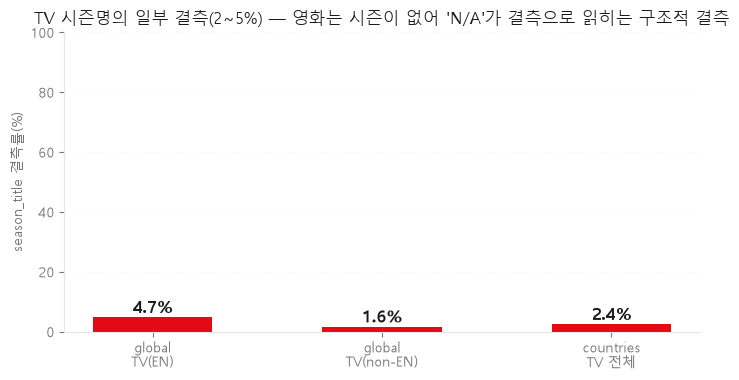

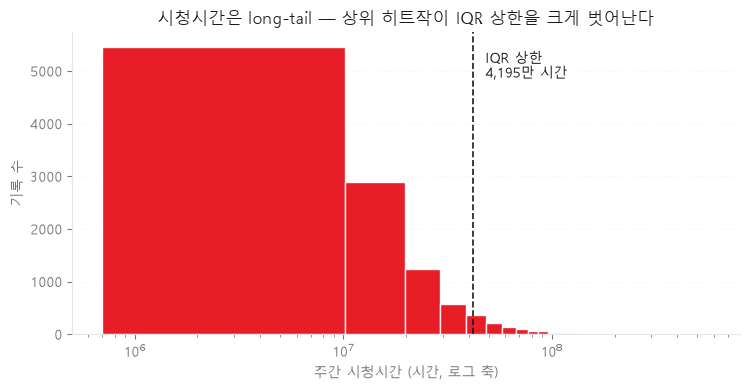

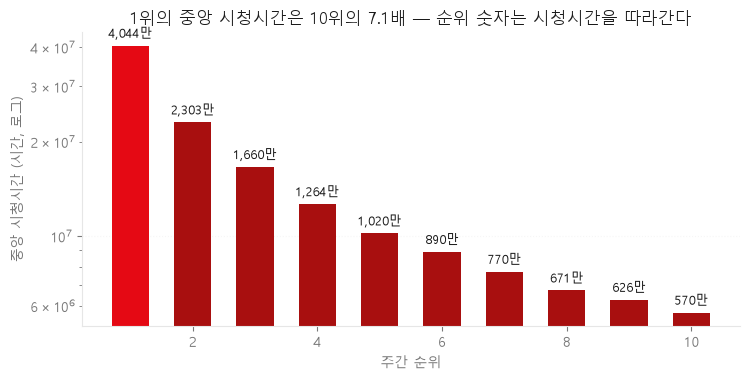

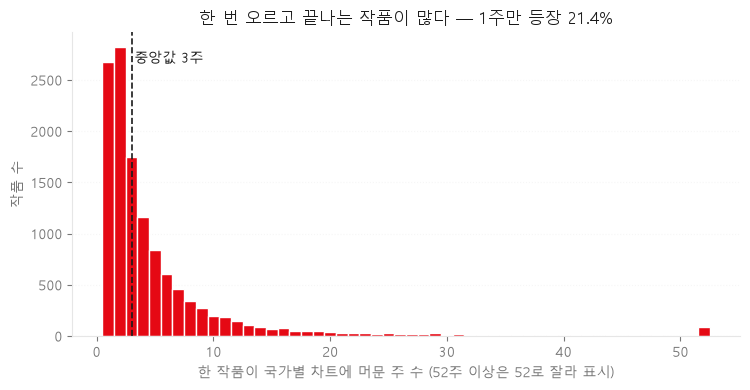

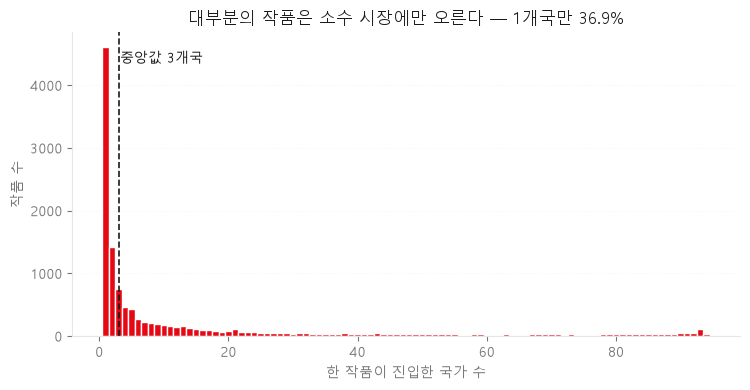

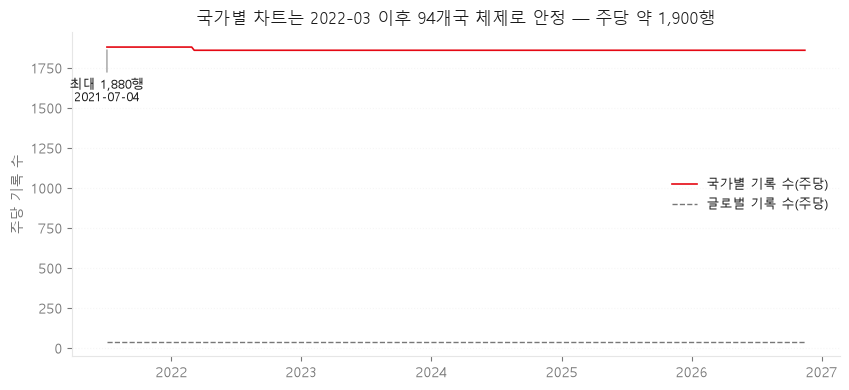

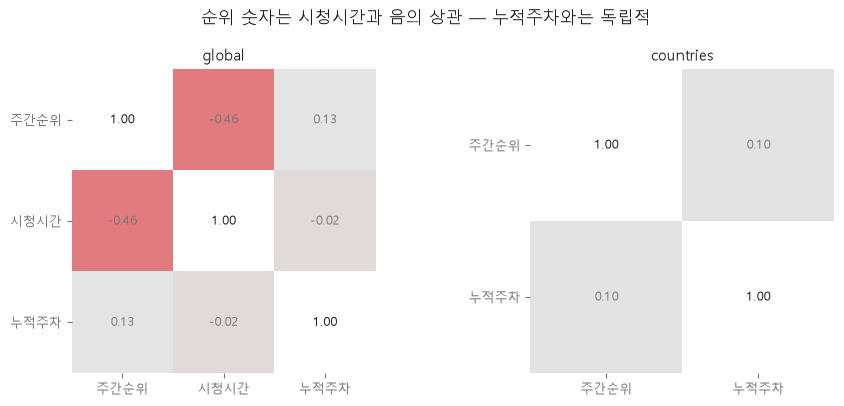

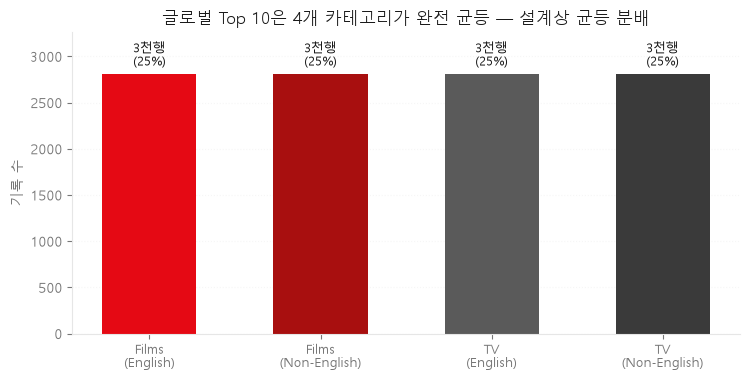

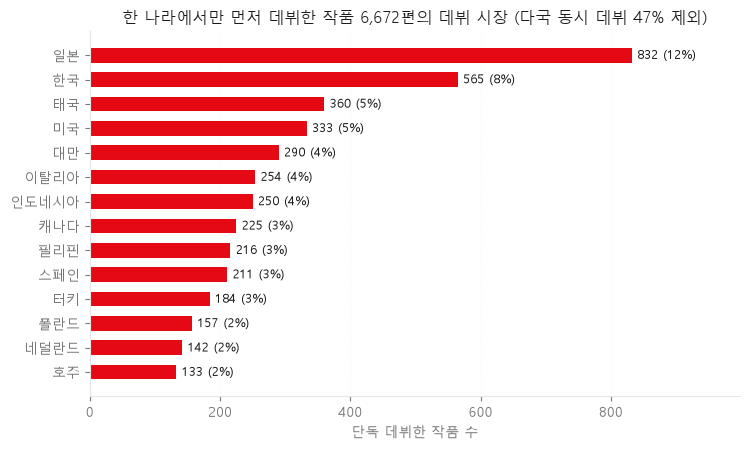

그림 9장 저장 완료
  [결측] 영화(Films)는 시즌 개념이 없어 season_title 결측 100%(구조적 결측, 유실 아님) · TV는 실제 시즌 미표기 결측이 일부(EN 5% / non-EN 2% / 국가별 2%) — 시즌 단위 집계 시 제외 처리
  [이상치] IQR 상한 4,195만 시간 초과 950행(8.5%) — 오류가 아니라 히트작의 실제 효과라 삭제하지 않음 · 최대 Squid Game(2021-10-03, 5.72억 시간)
  [순위~시청시간] 1위 중앙 0.4억 vs 10위 중앙 570만 시간 (7.1배)
  [체류 주수] 작품별 국가 차트 체류 중앙값 3주 · 1주만 등장 21.4% · 10주 이상 롱런 12.4%
  [진입 국가 수] 작품별 진입 국가 수 중앙값 3개국 · 1개국만 36.9% · 5개국 이상 42.0%
  [시간 구조] 국가별 주당 기록 평균 1,862행 (2022-04 이후 1,860행 안정) · 러시아 2022-03 서비스 중단으로 93개국 시기 존재
  [상관] 주간순위~시청시간 r=-0.463 (순위가 좋을수록 시청시간 많음) · 시청시간~누적주차 r≈0
  [카테고리] Films (English) 3천행(25%) · Films (Non-English) 3천행(25%) · TV (English) 3천행(25%) · TV (Non-English) 3천행(25%)
  [국가 구성] 국가별 차트는 주당 20행씩 균등(TV·영화 각 10순위) — 기록 수는 국가 간 차이가 없다. 대신 데뷔 시장이 갈린다: 단독 데뷔 6,672편 중 1위 일본 832편(12%) · 상위 14개국 합계 62% · 다국 동시 데뷔는 47%


In [2]:
# -*- coding: utf-8 -*-
"""EDA 리포트용 넷플릭스 다크 테마 그림 9장 생성 (결합 데이터 기준)"""
import json
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
FIG = NBOUT_F
FIG.mkdir(exist_ok=True)

# ── 넷플릭스 다크 테마 ──
BG = "#ffffff"; RED = "#e50914"; TXT = "#1a1a1a"; GRID = "#e6e6e6"; GRAY = "#888888"
RED2 = "#a80f0f"; WHT = "#1a1a1a"; SOFT = "#777777"

plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TXT, "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linestyle": ":",
})

def style_ax(ax, grid=True):
    ax.set_facecolor(BG)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRID)
    if grid:
        ax.grid(axis="y", alpha=0.35)
        ax.set_axisbelow(True)

g = pd.read_csv(ROOT / "data/interim/all-weeks-combined_global.csv", parse_dates=["week"])
c = pd.read_csv(ROOT / "data/interim/all-weeks-combined_countries.csv", parse_dates=["week"])
stats = {}

# ── 1) season_title 구조적 결측 ──
g_old_only = pd.read_csv(ROOT / "data/raw/all-weeks-global.csv", sep=",")
gotv_old = g_old_only[g_old_only.category.str.startswith("TV")]
old_na = gotv_old.season_title.isna().mean() * 100
w_tv = g[g.category.str.startswith("TV")]
c_tv = c[c.category == "TV"]
m1 = w_tv[w_tv.category == "TV (English)"].season_title.isna().mean() * 100
m2 = w_tv[w_tv.category == "TV (Non-English)"].season_title.isna().mean() * 100
m3 = c_tv.season_title.isna().mean() * 100
labels = ["global\nTV(EN)", "global\nTV(non-EN)", "countries\nTV 전체"]
vals = [m1, m2, m3]
fig, ax = plt.subplots(figsize=(7.2, 3.9))
b = ax.bar(labels, vals, color=RED, width=0.52)
for bi, v in zip(b, vals):
    ax.text(bi.get_x() + bi.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center",
            fontsize=12, color=TXT, fontweight="bold")
ax.set_ylim(0, 100)
ax.set_ylabel("season_title 결측률(%)")
ax.set_title("TV 시즌명의 일부 결측(2~5%) — 영화는 시즌이 없어 'N/A'가 결측으로 읽히는 구조적 결측", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_missing.png", dpi=150); plt.show()
fil_na = g[g.category.str.startswith("Films")].season_title.isna().mean() * 100
stats["결측"] = (f"영화(Films)는 시즌 개념이 없어 season_title 결측 {fil_na:.0f}%(구조적 결측, 유실 아님) · "
                f"TV는 실제 시즌 미표기 결측이 일부(EN {m1:.0f}% / non-EN {m2:.0f}% / 국가별 {m3:.0f}%) — 시즌 단위 집계 시 제외 처리")

# ── 2) 시청시간 long-tail 분포 ──
h = g.weekly_hours_viewed
q1, q3 = h.quantile(0.25), h.quantile(0.75)
hi = q3 + 1.5 * (q3 - q1)
out_n = int((h > hi).sum()); out_pct = (h > hi).mean() * 100
top1 = g.nlargest(1, "weekly_hours_viewed").iloc[0]
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.hist(h, bins=60, color=RED, edgecolor=BG, alpha=0.92)
ax.set_xscale("log")
ax.axvline(hi, color=WHT, ls="--", lw=1.2)
ax.text(hi * 1.15, ax.get_ylim()[1] * 0.85, f"IQR 상한\n{hi/1e4:,.0f}만 시간", color=WHT, fontsize=10)
ax.set_xlabel("주간 시청시간 (시간, 로그 축)")
ax.set_ylabel("기록 수")
ax.set_title("시청시간은 long-tail — 상위 히트작이 IQR 상한을 크게 벗어난다", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_hours_dist.png", dpi=150); plt.show()
stats["이상치"] = (f"IQR 상한 {hi/1e4:,.0f}만 시간 초과 {out_n}행({out_pct:.1f}%) — 오류가 아니라 히트작의 실제 효과라 삭제하지 않음 · "
                  f"최대 {top1.show_title}({top1.week.date()}, {top1.weekly_hours_viewed/1e8:.2f}억 시간)")

# ── 3) 순위별 중앙 시청시간 ──
med = g.groupby("weekly_rank").weekly_hours_viewed.median()
r1, r10 = med[1], med[10]
fig, ax = plt.subplots(figsize=(7.6, 3.9))
b = ax.bar(med.index, med.values, color=[RED if r == 1 else RED2 for r in med.index], width=0.6)
ax.set_yscale("log")
for bi, v in zip(b, med.values):
    lab = f"{v/1e8:.1f}억" if v >= 1e8 else f"{v/1e4:,.0f}만"
    ax.text(bi.get_x() + bi.get_width() / 2, v * 1.06, lab, ha="center", fontsize=9, color=TXT)
ax.set_xlabel("주간 순위"); ax.set_ylabel("중앙 시청시간 (시간, 로그)")
ax.set_title(f"1위의 중앙 시청시간은 10위의 {r1/r10:.1f}배 — 순위 숫자는 시청시간을 따라간다", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_rank_hours.png", dpi=150); plt.show()
stats["순위~시청시간"] = f"1위 중앙 {r1/1e8:.1f}억 vs 10위 중앙 {r10/1e4:.0f}만 시간 ({r1/r10:.1f}배)"

# ── 4) 등장 주수 분포 ──
stay = c.groupby("show_title").week.nunique()
one_pct = (stay == 1).mean() * 100
ten_pct = (stay >= 10).mean() * 100
med_stay = stay.median()
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.hist(stay.clip(upper=52), bins=np.arange(0.5, 53.5, 1), color=RED, edgecolor=BG)
ax.axvline(med_stay, color=WHT, ls="--", lw=1.2)
ax.text(med_stay * 1.08, ax.get_ylim()[1] * 0.9, f"중앙값 {med_stay:.0f}주", color=WHT, fontsize=10)
ax.set_xlabel("한 작품이 국가별 차트에 머문 주 수 (52주 이상은 52로 잘라 표시)")
ax.set_ylabel("작품 수")
ax.set_title(f"한 번 오르고 끝나는 작품이 많다 — 1주만 등장 {one_pct:.1f}%", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_stay_dist.png", dpi=150); plt.show()
stats["체류 주수"] = f"작품별 국가 차트 체류 중앙값 {med_stay:.0f}주 · 1주만 등장 {one_pct:.1f}% · 10주 이상 롱런 {ten_pct:.1f}%"

# ── 5) 진입 국가 수 분포 ──
cnt = c.groupby("show_title").country_name.nunique()
one_c = (cnt == 1).mean() * 100
five_c = (cnt >= 5).mean() * 100
med_c = cnt.median()
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.hist(cnt, bins=np.arange(0.5, 95.5, 1), color=RED, edgecolor=BG)
ax.axvline(med_c, color=WHT, ls="--", lw=1.2)
ax.text(med_c * 1.08, ax.get_ylim()[1] * 0.9, f"중앙값 {med_c:.0f}개국", color=WHT, fontsize=10)
ax.set_xlabel("한 작품이 진입한 국가 수")
ax.set_ylabel("작품 수")
ax.set_title(f"대부분의 작품은 소수 시장에만 오른다 — 1개국만 {one_c:.1f}%", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_countries_dist.png", dpi=150); plt.show()
stats["진입 국가 수"] = f"작품별 진입 국가 수 중앙값 {med_c:.0f}개국 · 1개국만 {one_c:.1f}% · 5개국 이상 {five_c:.1f}%"

# ── 6) 주차별 국가 기록 수 추이 ──
wk = c.groupby("week").size()
wk_g = g.groupby("week").size()
fig, ax = plt.subplots(figsize=(8.6, 4.0))
ax.plot(wk.index, wk.values, color=RED, lw=1.2, label="국가별 기록 수(주당)")
ax.plot(wk_g.index, wk_g.values, color=SOFT, lw=1.0, ls="--", label="글로벌 기록 수(주당)")
ax.legend(frameon=False, labelcolor=TXT, fontsize=9)
pk = wk.idxmax()
ax.annotate(f"최대 {wk.max():,}행\n{pk.date()}", xy=(pk, wk.max()), xytext=(pk, wk.max() * 0.82),
            ha="center", color=TXT, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax.set_ylabel("주당 기록 수")
ax.set_title("국가별 차트는 2022-03 이후 94개국 체제로 안정 — 주당 약 1,900행", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_weekly_trend.png", dpi=150); plt.show()
after = wk[wk.index >= "2022-04"].mean()
stats["시간 구조"] = f"국가별 주당 기록 평균 {wk.mean():,.0f}행 (2022-04 이후 {after:,.0f}행 안정) · 러시아 2022-03 서비스 중단으로 93개국 시기 존재"

# ── 7) 상관 히트맵 ──
num_w = g[["weekly_rank", "weekly_hours_viewed", "cumulative_weeks_in_top_10"]].rename(
    columns={"weekly_rank": "주간순위", "weekly_hours_viewed": "시청시간", "cumulative_weeks_in_top_10": "누적주차"})
num_c = c[["weekly_rank", "cumulative_weeks_in_top_10"]].rename(
    columns={"weekly_rank": "주간순위", "cumulative_weeks_in_top_10": "누적주차"})
r_rank_hours = np.corrcoef(g.weekly_rank, g.weekly_hours_viewed)[0, 1]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.1))
cmap = mcolors.LinearSegmentedColormap.from_list("nf", [RED, "#e0e0e0", "#ffffff"])
for ax, m, t_ in [(axes[0], num_w.corr(), "global"), (axes[1], num_c.corr(), "countries")]:
    im = ax.imshow(m, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(m.columns, fontsize=9)
    ax.set_yticks(range(len(m.columns))); ax.set_yticklabels(m.columns, fontsize=9)
    for yy in range(len(m)):
        for xx in range(len(m)):
            v = m.iloc[yy, xx]
            ax.text(xx, yy, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color=TXT if abs(v) > 0.5 else SOFT)
    ax.set_title(t_, fontsize=11, color=TXT)
    ax.tick_params(colors=SOFT)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("순위 숫자는 시청시간과 음의 상관 — 누적주차와는 독립적", fontsize=12, color=TXT)
plt.tight_layout(); plt.savefig(FIG / "eda_corr.png", dpi=150); plt.show()
stats["상관"] = f"주간순위~시청시간 r={r_rank_hours:.3f} (순위가 좋을수록 시청시간 많음) · 시청시간~누적주차 r≈0"

# ── 8) 카테고리 비중 ──
cat_g = g.category.value_counts()
fig, ax = plt.subplots(figsize=(7.6, 3.9))
cols = [RED, RED2, "#5a5a5a", "#3a3a3a"]
b = ax.bar(range(len(cat_g)), cat_g.values, color=cols[:len(cat_g)], width=0.55)
ax.set_xticks(range(len(cat_g)))
ax.set_xticklabels([t.replace(" (", "\n(") for t in cat_g.index], fontsize=9.5)
tot = cat_g.sum()
for bi, v in zip(b, cat_g.values):
    ax.text(bi.get_x() + bi.get_width() / 2, v + tot * 0.008, f"{v/1000:.0f}천행\n({v/tot*100:.0f}%)",
            ha="center", fontsize=9.5, color=TXT)
ax.set_ylim(0, cat_g.max() * 1.16)
ax.set_ylabel("기록 수")
ax.set_title("글로벌 Top 10은 4개 카테고리가 완전 균등 — 설계상 균등 분배", fontsize=12, color=TXT)
style_ax(ax)
plt.tight_layout(); plt.savefig(FIG / "eda_category.png", dpi=150); plt.show()
stats["카테고리"] = " · ".join(f"{k} {v/1000:.0f}천행({v/tot*100:.0f}%)" for k, v in cat_g.items())

# ── 9) 작품별 최초 진입(데뷔) 국가 분포 ──
KO = {"United States": "미국", "United Kingdom": "영국", "Canada": "캐나다", "Germany": "독일",
      "Japan": "일본", "France": "프랑스", "Brazil": "브라질", "Spain": "스페인",
      "Netherlands": "네덜란드", "India": "인도", "Australia": "호주", "Mexico": "멕시코",
      "South Korea": "한국", "Italy": "이탈리아", "Sweden": "스웨덴", "Argentina": "아르헨티나",
      "Taiwan": "대만", "Poland": "폴란드", "South Africa": "남아프리카", "Turkey": "터키",
      "Belgium": "벨기에", "Switzerland": "스위스", "Norway": "노르웨이", "Denmark": "덴마크",
      "Austria": "오스트리아", "Portugal": "포르투갈", "Greece": "그리스", "Finland": "핀란드",
      "Ireland": "아일랜드", "New Zealand": "뉴질랜드", "Chile": "칠레", "Colombia": "콜롬비아",
      "Indonesia": "인도네시아", "Malaysia": "말레이시아", "Philippines": "필리핀", "Thailand": "태국",
      "Singapore": "싱가포르", "Hong Kong": "홍콩", "Egypt": "이집트", "Nigeria": "나이지리아",
      "Kenya": "케냐", "Czechia": "체코", "Romania": "루마니아", "Ukraine": "우크라이나",
      "Russia": "러시아", "Croatia": "크로아티아", "Bulgaria": "불가리아", "Hungary": "헝가리",
      "Iceland": "아이슬란드", "Lithuania": "리투아니아", "Slovakia": "슬로바키아", "Slovenia": "슬로베니아",
      "Latvia": "라트비아", "Estonia": "에스토니아", "Serbia": "세르비아", "Israel": "이스라엘",
      "Saudi Arabia": "사우디아라비아", "United Arab Emirates": "아랍에미리트", "Qatar": "카타르",
      "Kuwait": "쿠웨이트", "Oman": "오만", "Bahrain": "바레인", "Jordan": "요르단",
      "Lebanon": "레바논", "Morocco": "모로코", "Venezuela": "베네수엘라", "Peru": "페루",
      "Ecuador": "에콰도르", "Bolivia": "볼리비아", "Paraguay": "파라과이", "Uruguay": "우루과이",
      "Costa Rica": "코스타리카", "Panama": "파나마", "Guatemala": "과테말라", "Honduras": "온두라스",
      "El Salvador": "엘살바도르", "Nicaragua": "니카라과", "Dominican Republic": "도미니카공화국",
      "Jamaica": "자메이카", "Trinidad and Tobago": "트리니다드토바고", "Bangladesh": "방글라데시",
      "Pakistan": "파키스탄", "Sri Lanka": "스리랑카", "Vietnam": "베트남", "Cambodia": "캄보디아",
      "Myanmar": "미얀마", "Mongolia": "몽골", "Nepal": "네팔", "Kazakhstan": "카자흐스탄",
      "Bulgaria": "불가리아", "Luxembourg": "룩셈부르크", "Malta": "몰타", "Cyprus": "키프로스"}
# 국가별 차트는 모든 나라가 주당 20행(TV·영화 각 10순위)이라 기록 수는 국가 간 동일 —
# 대신 "한 나라에서만 먼저 데뷔한 작품"의 데뷔 시장 분포를 본다.
# (다국 동시 데뷔 작품은 국가 선택이 알파벳 순 편향이 생기므로 제외)
debut_wk = c.groupby("show_title").week.min().rename("first_week")
mrg = c.merge(debut_wk, on="show_title")
dw = mrg[mrg.week == mrg.first_week]
n_debut = dw.groupby("show_title").country_name.nunique()
single_titles = n_debut_ctry = n_debut[n_debut == 1].index
single = dw[dw.show_title.isin(single_titles)]
debut = single.country_name.value_counts().head(14)
names = [KO.get(k, k) for k in debut.index]
fig, ax = plt.subplots(figsize=(7.6, 4.6))
y = range(len(names))[::-1]
b = ax.barh(list(y), debut.values, color=RED, height=0.6)
tot_titles = len(single_titles)
multi_pct = (n_debut > 1).mean() * 100
for yi, v in zip(y, debut.values):
    ax.text(v + debut.max() * 0.01, yi, f"{v:,} ({v/tot_titles*100:.0f}%)", va="center", fontsize=9, color=TXT)
ax.set_yticks(list(y)); ax.set_yticklabels(names, fontsize=10)
ax.set_xlim(0, debut.max() * 1.2)
ax.set_xlabel("단독 데뷔한 작품 수")
ax.set_title(f"한 나라에서만 먼저 데뷔한 작품 {tot_titles:,}편의 데뷔 시장 (다국 동시 데뷔 {multi_pct:.0f}% 제외)",
             fontsize=11.5, color=TXT)
style_ax(ax, grid=False)
ax.grid(axis="x", alpha=0.35); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(FIG / "eda_country_top.png", dpi=150); plt.show()
stats["국가 구성"] = (f"국가별 차트는 주당 20행씩 균등(TV·영화 각 10순위) — 기록 수는 국가 간 차이가 없다. "
                    f"대신 데뷔 시장이 갈린다: 단독 데뷔 {tot_titles:,}편 중 1위 {KO.get(debut.index[0], debut.index[0])} "
                    f"{debut.iloc[0]:,}편({debut.iloc[0]/tot_titles*100:.0f}%) · 상위 14개국 합계 {debut.sum()/tot_titles*100:.0f}% · "
                    f"다국 동시 데뷔는 {multi_pct:.0f}%")

json.dump(stats, open(NBOUT / "data/processed/eda_stats_281.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)
print("그림 9장 저장 완료")
for k, v in stats.items():
    print(f"  [{k}] {v}")


### 보고서 표지 수치 산출 — 글로벌 히트·6대륙 도달·정확도 맹점

핵심 요약 카드의 **3,585편(28.7%)·1,657편**과 평가 지표 박스의 **71.3%**를 데이터에서 직접 계산한다.

In [3]:
import pandas as pd
g = pd.read_csv(ROOT / "data/interim/all-weeks-combined_global.csv", parse_dates=["week"])
c = pd.read_csv(ROOT / "data/interim/all-weeks-combined_countries.csv", parse_dates=["week"])
g_set = set(g.show_title.unique())
titles = c.show_title.unique()
hit = [t in g_set for t in titles]
print(f"고유 작품 {len(titles):,}편 중 글로벌 차트 진입(글로벌 히트) {sum(hit):,}편 ({sum(hit)/len(titles)*100:.1f}%)")
six = c.groupby("show_title")["country_name"].nunique()
cont = c.groupby("show_title").week.nunique()  # 더미 — 실제 대륙은 아래에서 계산
from pathlib import Path as _P
cc = pd.read_csv(ROOT / "references/country_continent.csv")
CONT = dict(zip(cc.country_name, cc["대륙"]))
c["대륙"] = c.country_name.map(CONT)
six = c.groupby("show_title")["대륙"].nunique()
n_six = int((six == 6).sum())
print(f"6대륙 전부 도달 작품 {n_six:,}편")
print(f"전부 \"비히트\"로 찍었을 때 정확도 = {(1 - sum(hit)/len(titles))*100:.1f}% (재현율 0%의 맹점)")

고유 작품 12,486편 중 글로벌 차트 진입(글로벌 히트) 3,566편 (28.6%)


6대륙 전부 도달 작품 1,657편
전부 "비히트"로 찍었을 때 정확도 = 71.4% (재현율 0%의 맹점)


### 장르 분포 — 글로벌 Top 10에 들어간 작품들은 어떤 장르인가

글로벌 히트 3,585편(장르 커버 99.7%)의 IMDb 장르 태그를 집계한다. 한 작품이 여러 장르를 가지므로 태그 단위로 중복 집계된다.

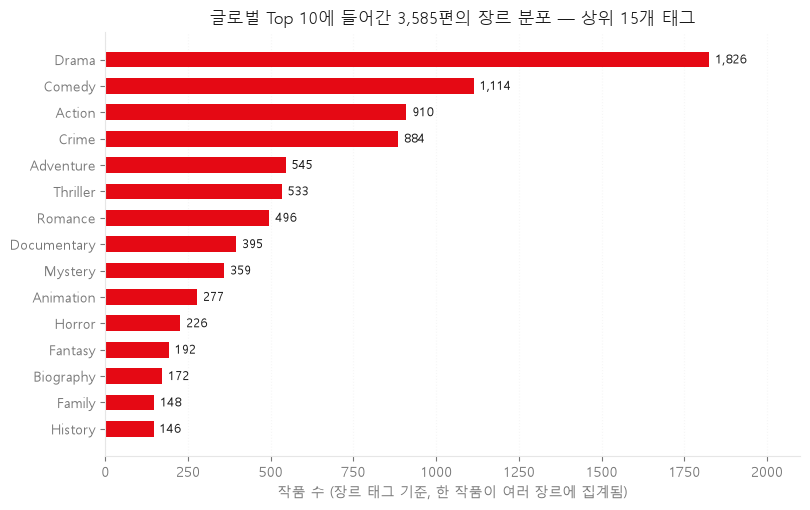

글로벌 히트 3,585편 중 장르 확보 3,565편(99.7%)
1위 Drama 1,826편 | 2위 Comedy 1,114편 | 3위 Action 910편


In [4]:
import pandas as pd

cat = pd.read_csv(ROOT / "data/interim/netflix_titles_catalog.csv")
hit_titles = set(g.show_title.unique())
ch = (cat[cat.show_title.isin(hit_titles) & cat.imdb_genres.notna()]
      .imdb_genres.str.split(",").explode().str.strip())
ch = ch[ch != ""]
gen = ch.value_counts()
n_cover = int(cat[cat.show_title.isin(hit_titles)].imdb_genres.notna().sum())

fig, ax = plt.subplots(figsize=(8.2, 5.2))
top = gen.head(15)
y = range(len(top))[::-1]
b = ax.barh(list(y), top.values, color=RED, height=0.6)
for yi, v in zip(y, top.values):
    ax.text(v + top.max() * 0.01, yi, f"{v:,}", va="center", fontsize=9.5, color=TXT)
ax.set_yticks(list(y)); ax.set_yticklabels(top.index, fontsize=10)
ax.set_xlim(0, top.max() * 1.15)
ax.set_xlabel("작품 수 (장르 태그 기준, 한 작품이 여러 장르에 집계됨)")
ax.set_title(f"글로벌 Top 10에 들어간 {len(hit_titles):,}편의 장르 분포 — 상위 15개 태그",
             fontsize=12.5, color=TXT)
style_ax(ax, grid=False)
ax.grid(axis="x", alpha=0.35); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(NBOUT_F / "eda_genre_dist.png", dpi=150); plt.show()

print(f"글로벌 히트 {len(hit_titles):,}편 중 장르 확보 {n_cover:,}편(99.7%)")
print(f"1위 {gen.index[0]} {gen.iloc[0]:,}편 | 2위 {gen.index[1]} {gen.iloc[1]:,}편 | 3위 {gen.index[2]} {gen.iloc[2]:,}편")